<a href="https://colab.research.google.com/github/Diana231861/Proyecto-Vision-Computacional-Procesamiento-de-im-genes/blob/main/Proyecto_Vision_Computacional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto: Preprocesamiento de dataset de imagenes**

##Integrantes:


## *   Accostupa Alcca Diana Azumi    231861
## *   Lazo Florez Yely               230252



In [48]:
# Importamos librerias
import os
import glob
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path

# 1. Descripción del dataset

Los datos recopilados al inicio del estudio incluyen imágenes de ecografía mamaria de mujeres de entre 25 y 75 años. Estos datos se recopilaron en 2018. El número de pacientes es de 600 mujeres. El conjunto de datos consta de 780 imágenes con un tamaño promedio de 500 x 500 píxeles. Las imágenes están en formato PNG. Las imágenes de referencia se presentan junto con las imágenes originales. Las imágenes se clasifican en tres categorías: normales, benignas y malignas.

Si utiliza este conjunto de datos, cite la siguiente referencia:
Al-Dhabyani W, Gomaa M, Khaled H, Fahmy A. Dataset of breast ultrasound images. Data in Brief. 2020 Feb;28:104863. DOI: 10.1016/j.dib.2019.104863.

# 2. Cargar dataset

In [35]:
# Dataset de imagenes (muestras normales, benignas y malignas)
path = kagglehub.dataset_download(
    "aryashah2k/breast-ultrasound-images-dataset"
)

print("Ruta del dataset:", path)

categorias = ["normal", "benign", "malignant"]

# Localizar todas las imágenes PNG
archivos_png = glob.glob(
    os.path.join(path, "**", "*.png"),
    recursive=True
)

# Separar imágenes originales y máscaras
mascaras = [
    f for f in archivos_png
    if re.search(r"_mask(?:_\d+)?$", Path(f).stem, re.IGNORECASE)
]

imagenes = [
    f for f in archivos_png
    if not re.search(r"_mask(?:_\d+)?$", Path(f).stem, re.IGNORECASE)
]

print("Imágenes originales:", len(imagenes))
print("Archivos de máscaras:", len(mascaras))


Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
Ruta del dataset: /kaggle/input/breast-ultrasound-images-dataset
Imágenes originales: 780
Archivos de máscaras: 798


In [36]:
# Crear un índice de máscaras por nombre base
indice_mascaras = {}

for ruta in mascaras:
    nombre = Path(ruta).stem

    # Ejemplo: benign (2)_mask_1 - benign (2)
    base = re.sub(
        r"_mask(?:_\d+)?$",
        "",
        nombre,
        flags=re.IGNORECASE
    )

    indice_mascaras.setdefault(base, []).append(ruta)


# Construir pares imagen-máscara
pares = []

for ruta_img in imagenes:
    nombre = Path(ruta_img).stem

    rutas_mask = indice_mascaras.get(nombre, [])

    # Se requieren máscaras para evaluar segmentación de lesiones
    if rutas_mask:
        categoria = next(
            (c for c in categorias
             if c in str(Path(ruta_img).parts).lower()),
            "desconocida"
        )

        pares.append({
            "imagen": ruta_img,
            "mascaras": sorted(rutas_mask),
            "categoria": categoria
        })

print("Pares imagen-máscara:", len(pares))

for par in pares[:5]:
    print(
        os.path.basename(par["imagen"]),
        "->",
        [os.path.basename(m) for m in par["mascaras"]]
    )

Pares imagen-máscara: 780
benign (2).png -> ['benign (2)_mask.png']
benign (285).png -> ['benign (285)_mask.png']
benign (300).png -> ['benign (300)_mask.png']
benign (390).png -> ['benign (390)_mask.png']
benign (357).png -> ['benign (357)_mask.png']


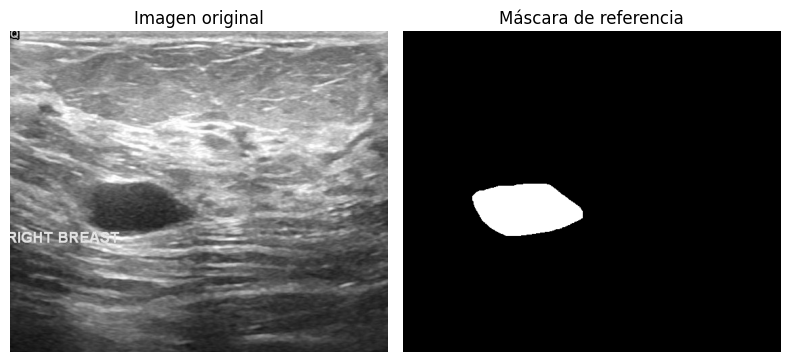

In [69]:
def cargar_imagen_y_mascara(par):
    imagen = cv2.imread(
        par["imagen"],
        cv2.IMREAD_GRAYSCALE
    )

    if imagen is None:
        raise ValueError(f"No se pudo leer: {par['imagen']}")

    # Combinar las máscaras asociadas, si hay más de una
    mascara_combinada = np.zeros_like(imagen, dtype=np.uint8)

    for ruta_mask in par["mascaras"]:
        mask = cv2.imread(
            ruta_mask,
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            continue

        if mask.shape != imagen.shape:
            mask = cv2.resize(
                mask,
                (imagen.shape[1], imagen.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )

        mascara_combinada = cv2.bitwise_or(
            mascara_combinada,
            cv2.threshold(
                mask, 127, 255, cv2.THRESH_BINARY
            )[1]
        )

    return imagen, mascara_combinada


# Visualizar un ejemplo con máscara
par = pares[0]
original, mascara_real = cargar_imagen_y_mascara(par)

fig, axes = plt.subplots(1, 2, figsize=(8, 10))

axes[0].imshow(original, cmap="gray")
axes[0].set_title("Imagen original")

axes[1].imshow(mascara_real, cmap="gray")
axes[1].set_title("Máscara de referencia")


for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 3. Preprocesamiento

## 3.0. Selección de un ejemplo por categoría
Se toma una imagen (con su máscara) de cada categoría: **Normal, Benigno y Maligno**. Todas las etapas siguientes se muestran sobre estos tres ejemplos.

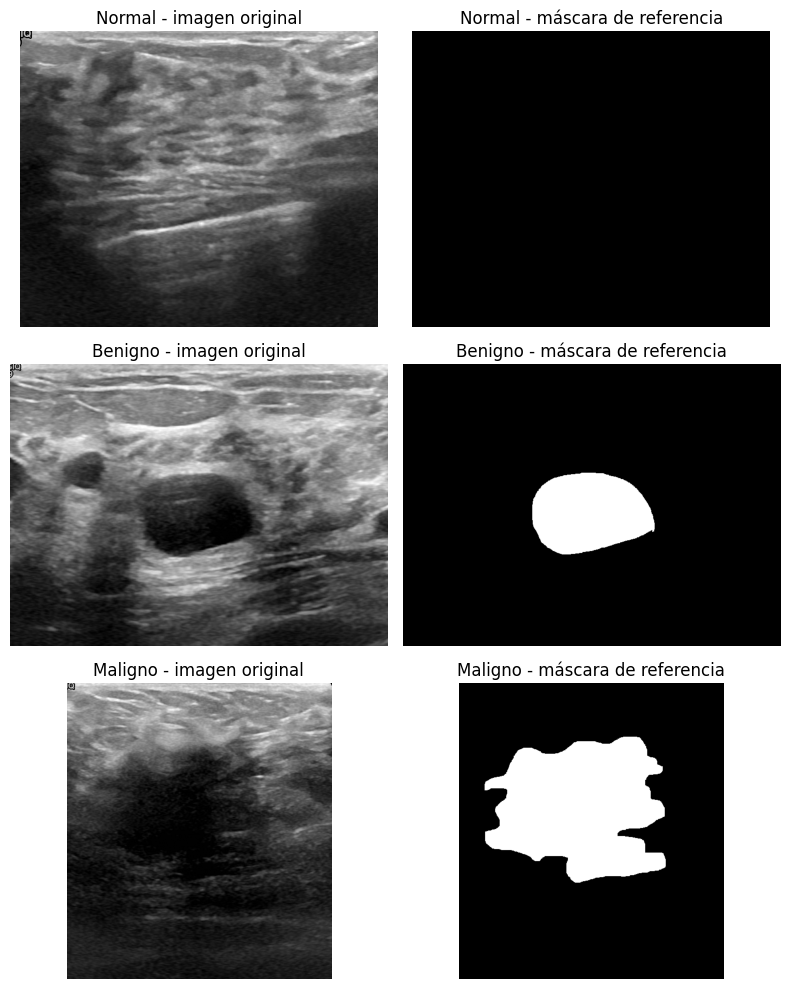

In [68]:
def elegir_ejemplos(pares, semilla=32):
    rng = np.random.default_rng(semilla)
    ejemplos = {}
    for cat in categorias:
        candidatos = sorted(
            [p for p in pares if p["categoria"] == cat],
            key=lambda p: p["imagen"]
        )
        for idx in rng.permutation(len(candidatos)):
            par = candidatos[idx]
            _, m = cargar_imagen_y_mascara(par)
            if cat == "normal" or m.sum() > 0:
                ejemplos[cat] = par
                break
    return ejemplos

NOMBRES = {"normal": "Normal", "benign": "Benigno", "malignant": "Maligno"}
ejemplos = elegir_ejemplos(pares)
datos = {cat: cargar_imagen_y_mascara(par) for cat, par in ejemplos.items()}

fig, axes = plt.subplots(3, 2, figsize=(8, 10))
for fila, cat in enumerate(categorias):
    img, msk = datos[cat]
    axes[fila, 0].imshow(img, cmap="gray")
    axes[fila, 0].set_title(f"{NOMBRES[cat]} - imagen original")
    axes[fila, 1].imshow(msk, cmap="gray")
    axes[fila, 1].set_title(f"{NOMBRES[cat]} - máscara de referencia")
    for ax in axes[fila]: ax.axis("off")
plt.tight_layout(); plt.show()

## 3.1. Eliminación de anotaciones (texto y marcas del equipo)
Las imágenes contienen texto (por ejemplo *RIGHT BREAST*) y marcadores brillantes. Se detectan con un **top-hat morfológico** (estructuras brillantes y finas) y se rellenan con *inpainting*, para que no interfieran con la segmentación.

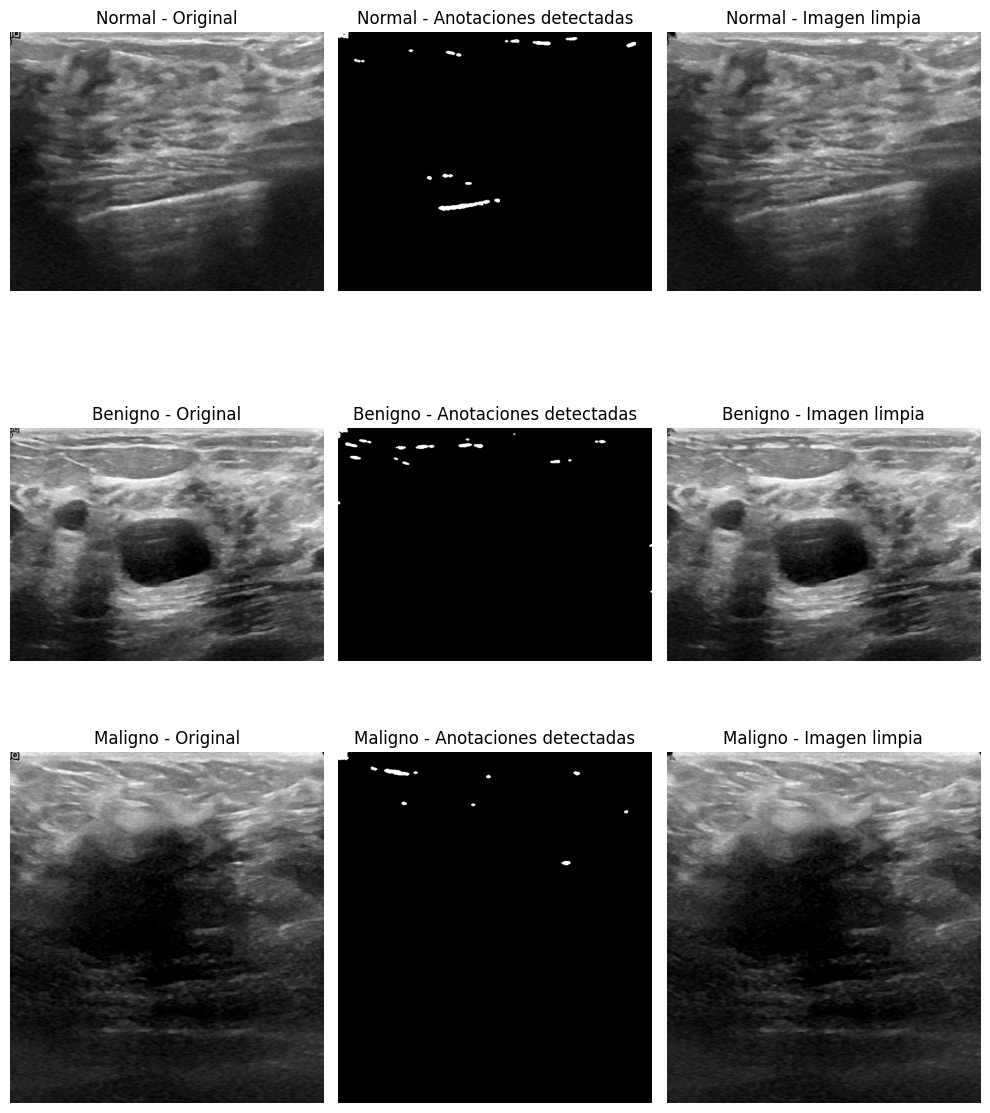

In [71]:
def quitar_anotaciones(img):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, k)

    # Píxeles muy brillantes y de apariencia "fina"
    m = ((tophat > 80) & (img > 170)).astype(np.uint8) * 255
    m = cv2.morphologyEx(
        m, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    )

    # Solo componentes pequeños (letras); evita borrar tejido brillante grande
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    texto = np.zeros_like(m)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < 1500:
            texto[lab == i] = 255

    texto = cv2.dilate(
        texto, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    )
    limpia = cv2.inpaint(img, texto, 3, cv2.INPAINT_TELEA)
    return limpia, texto


fig, axes = plt.subplots(3, 3, figsize=(10, 12))
for fila, cat in enumerate(categorias):
    img, _ = datos[cat]
    limpia, texto = quitar_anotaciones(img)
    for ax, (t, im) in zip(axes[fila], [
        ("Original", img), ("Anotaciones detectadas", texto), ("Imagen limpia", limpia)
    ]):
        ax.imshow(im, cmap="gray"); ax.set_title(f"{NOMBRES[cat]} - {t}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3.2. Eliminación de ruido: filtros de mediana, gaussiano y bilateral
El ruido *speckle* del ultrasonido se reduce con **mediana (5×5) + gaussiano (5×5)**, que es la combinación usada en el resto del pipeline. Se muestran también los tres filtros por separado para compararlos.

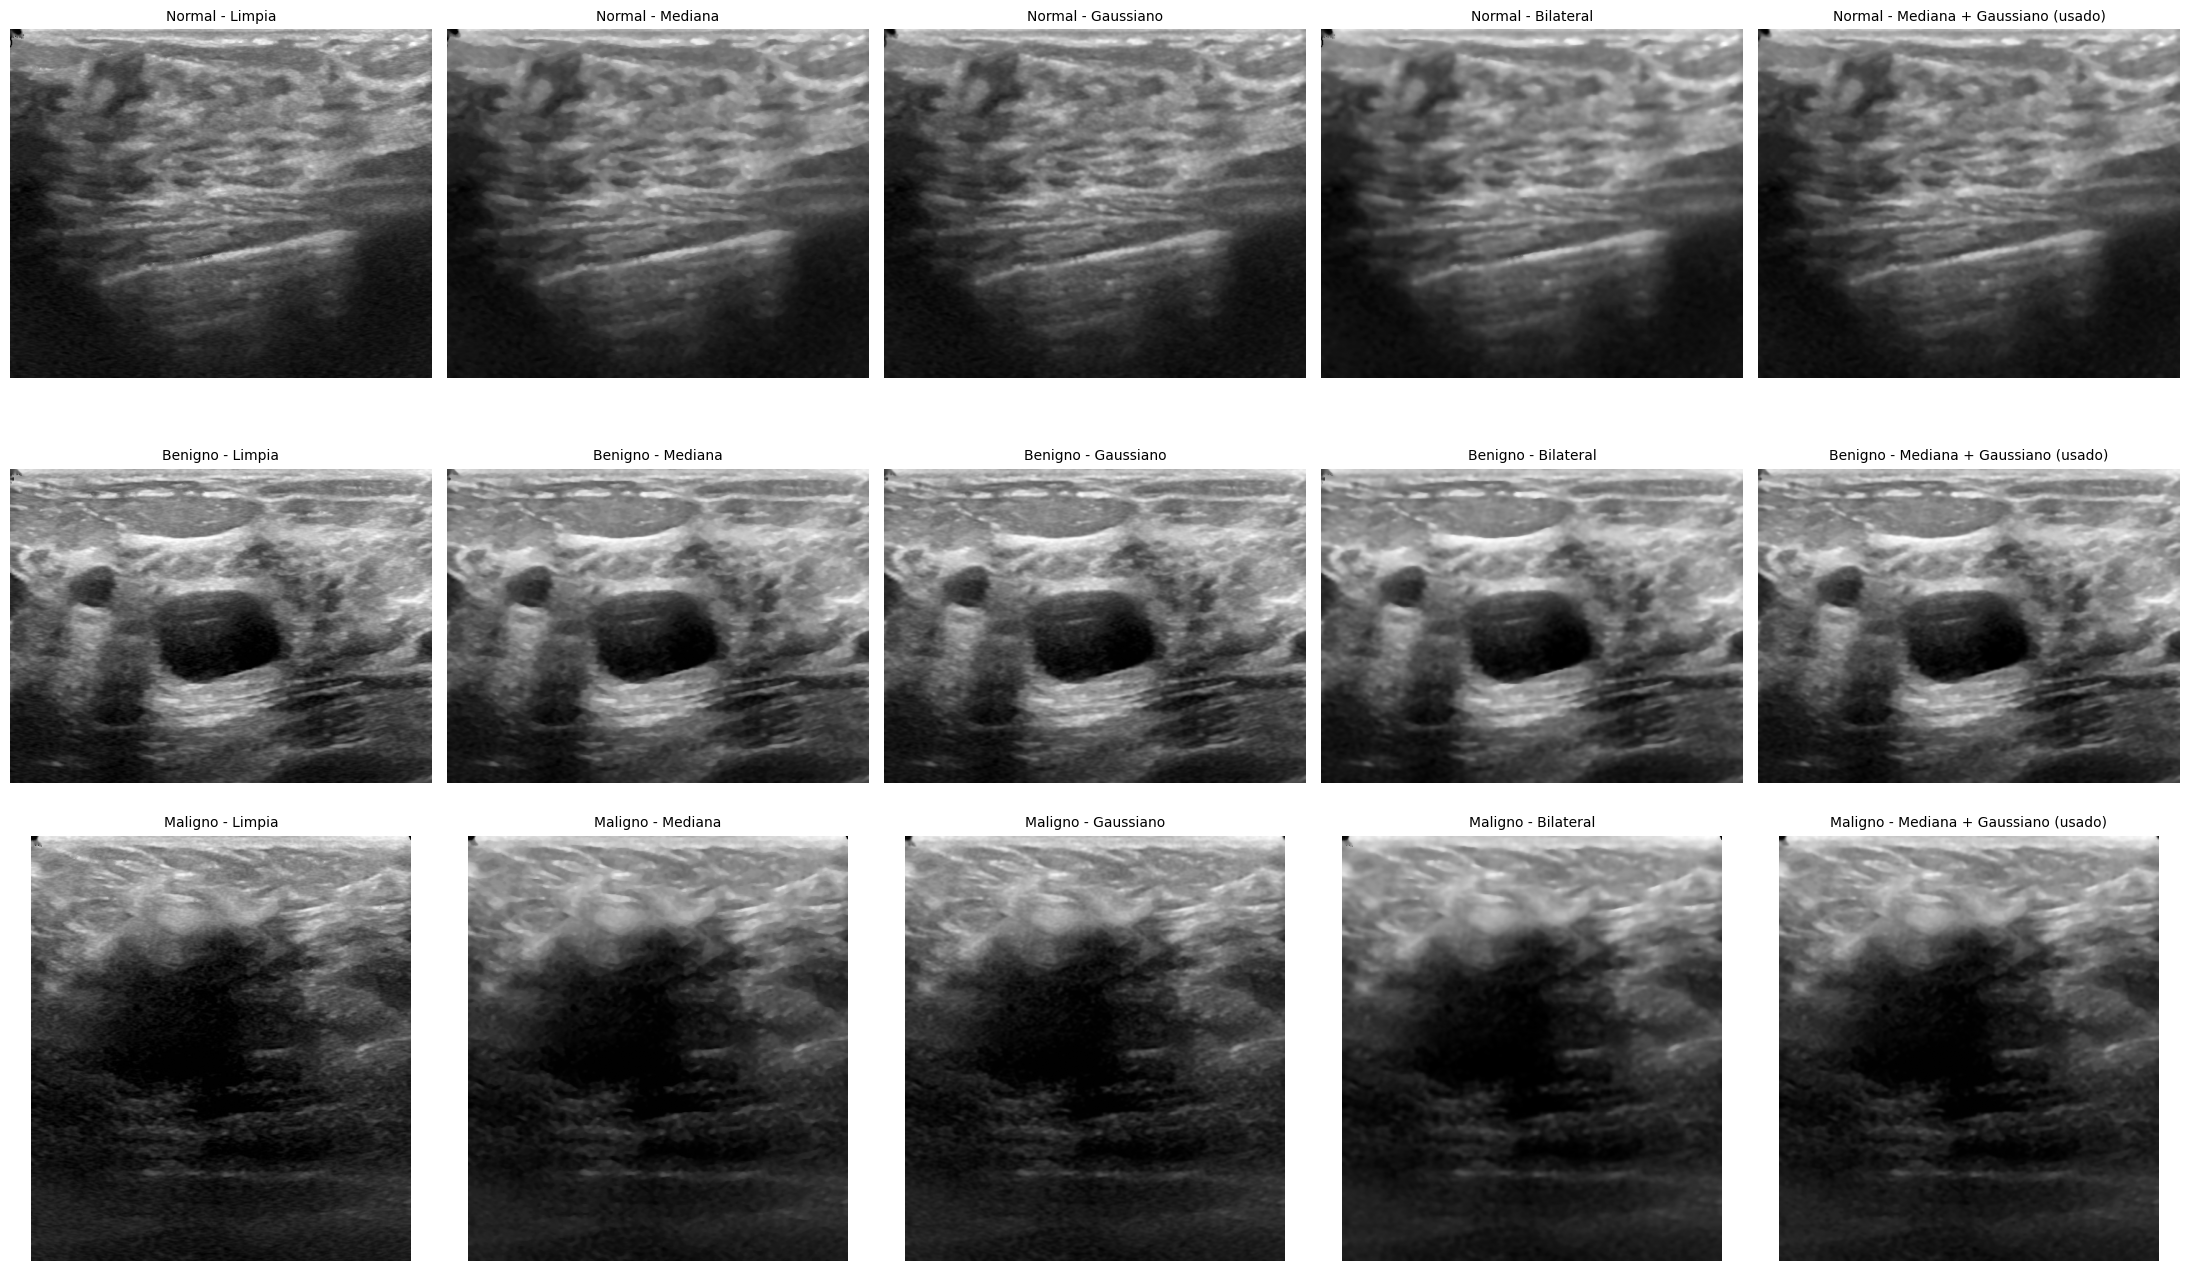

In [40]:
def aplicar_filtros(imagen):
    mediana = cv2.medianBlur(imagen, 5)
    gaussiano = cv2.GaussianBlur(imagen, (5, 5), 0)
    bilateral = cv2.bilateralFilter(imagen, 9, 50, 50)
    return {
        "Original": imagen,
        "Mediana": mediana,
        "Gaussiano": gaussiano,
        "Bilateral": bilateral
    }

def reducir_ruido(img):
    """Filtro final del pipeline: mediana + gaussiano."""
    return cv2.GaussianBlur(cv2.medianBlur(img, 5), (5, 5), 0)


limpias = {cat: quitar_anotaciones(datos[cat][0])[0] for cat in categorias}
suavizadas = {cat: reducir_ruido(limpias[cat]) for cat in categorias}

fig, axes = plt.subplots(3, 5, figsize=(22, 13))
for fila, cat in enumerate(categorias):
    resultados = aplicar_filtros(limpias[cat])
    resultados["Mediana + Gaussiano (usado)"] = suavizadas[cat]
    del resultados["Original"]
    todos = {"Limpia": limpias[cat], **resultados}
    for ax, (t, im) in zip(axes[fila], todos.items()):
        ax.imshow(im, cmap="gray"); ax.set_title(f"{NOMBRES[cat]} - {t}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 3.3. Morfología Matemática y Segmentación a imágenes binarias
La lesión es una zona **hipoecoica** (más oscura que su entorno), pero en las imágenes reales es irregular, puede tocar el borde inferior/lateral y se confunde con la **sombra acústica posterior**. Por eso el método es *parametrizable* y se ajusta con la máscara real en el conjunto de validación:

1. Suavizado fuerte (gaussiano σ=6) y **barrido de umbrales por percentiles** (4 %–35 % de píxeles más oscuros).
2. Para cada umbral: apertura, cierre y relleno de huecos → **candidatos** a lesión.
3. De cada candidato se miden **contraste con su anillo exterior, solidez, tamaño, ancho y forma**.
4. Se elige el mejor candidato que cumpla los criterios (`PARAMS`). Si ninguno los cumple, la imagen se considera **sin lesión** (máscara vacía, como en la categoría Normal).
5. El candidato se **refina** haciéndolo crecer hasta el borde real (umbral entre interior y anillo), con un tope de crecimiento para no invadir la sombra posterior.

In [53]:
def rellenar_huecos(m):
    h, w = m.shape
    ff = m.copy()
    pad = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(ff, pad, (0, 0), 255)
    return m | cv2.bitwise_not(ff)


def binaria_por_percentil(img, p, sigma=6):
    """Binaria de zonas oscuras: píxeles por debajo del percentil p."""
    s = cv2.GaussianBlur(img, (0, 0), sigma)
    valid = img > 5
    t = np.percentile(s[valid], p)
    return ((s <= t) & valid).astype(np.uint8) * 255


def candidatos_lesion(img, percentiles=(4, 6, 8, 10, 12, 15, 18, 22, 26, 30, 35), sigma=6):
    """Genera candidatos con sus características (se calculan una sola vez por imagen)."""
    h, w = img.shape
    s = cv2.GaussianBlur(img, (0, 0), sigma)
    valid = img > 5
    k_o = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    k_c = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    k_r = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))

    cands, vistos = [], set()
    for p in percentiles:
        t = np.percentile(s[valid], p)
        b = ((s <= t) & valid).astype(np.uint8) * 255
        b = cv2.morphologyEx(b, cv2.MORPH_OPEN, k_o)
        b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, k_c)
        b = rellenar_huecos(b)

        n, lab, st, cen = cv2.connectedComponentsWithStats(b)
        for i in range(1, n):
            a = st[i, cv2.CC_STAT_AREA]
            x, y, bw, bh = st[i, :4]
            if a < 0.005 * h * w:      # muy pequeño o pegado al borde superior
                continue

            margin = 5  # margen de píxeles al borde
            if y <= margin or (y + bh) >= (h - margin) or x <= margin or (x + bw) >= (w - margin):
                continue
            clave = (int(cen[i][0] // 8), int(cen[i][1] // 8), int(a // (0.02 * h * w)))
            if clave in vistos:                  # evitar candidatos repetidos entre umbrales
                continue
            vistos.add(clave)

            c = (lab == i).astype(np.uint8)
            cnt = cv2.findContours(c, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0][0]
            solidez = a / max(cv2.contourArea(cv2.convexHull(cnt)), 1)
            anillo = (cv2.dilate(c, k_r) > 0) & (c == 0) & valid
            if anillo.sum() < 50:
                continue
            contraste = float(img[anillo].mean() - img[c > 0].mean())
            if contraste < 8 or solidez < 0.5:
                continue

            cands.append({
                "mask": np.packbits(c.astype(bool)),   # guardada compacta
                "area": a / (h * w),
                "solidez": float(solidez),
                "contraste": contraste,
                "ancho": bw / w,
                "alargada": (bh > 3 * bw) or (bw > 3 * bh),
            })
    return cands


In [54]:
PARAMS = {
    "contraste_min": 12,    # Permite lesiones con contraste moderado
    "area_min": 0.005,      # Permite lesiones medianas/pequeñas
    "area_max": 0.80,       # Aumentado para lesiones malignas grandes
    "solidez_min": 0.35,    # Reducido (de 0.70/0.50) para aceptar contornos muy irregulares
    "ancho_max": 0.8,       # Permite lesiones extendidas horizontalmente
    "frac": 0.6,
    "iters": 2
}

In [64]:
def elegir_candidato(cands, params=None):
    params = params or PARAMS
    mejor, mejor_s = None, 0

    for c in cands:
        if (c["contraste"] < params["contraste_min"]
            or c["solidez"] < params["solidez_min"]
            or not (params["area_min"] <= c["area"] <= params["area_max"])
            or c["ancho"] > params["ancho_max"]):
            continue

        # Le damos peso al contraste y al área, sin penalizar si la forma no es redonda
        score = c["contraste"] * np.sqrt(c["area"]) * (c["solidez"] + 0.2)

        if score > mejor_s:
            mejor, mejor_s = c, score

    return mejor


def desempaquetar(c, shape):
    h, w = shape
    return (np.unpackbits(c["mask"])[:h * w].reshape(h, w) * 255).astype(np.uint8)


def _refinar(img, semilla, frac):
    s = cv2.GaussianBlur(img, (0, 0), 3)
    anillo = (cv2.dilate(semilla, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))) > 0) & (semilla == 0)
    adentro, afuera = s[semilla > 0].mean(), s[anillo].mean()
    t = adentro + frac * (afuera - adentro)

    zona = cv2.dilate(semilla, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (91, 91)))
    b = ((s <= t) & (zona > 0)).astype(np.uint8) * 255
    b = cv2.morphologyEx(b, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    b = cv2.morphologyEx(b, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))

    n, lab = cv2.connectedComponents(b)
    sol = lab[semilla > 0]
    sol = sol[sol > 0]
    if len(sol) == 0:
        return semilla
    b = ((lab == np.bincount(sol).argmax()) * 255).astype(np.uint8)
    b = rellenar_huecos(b)
    b = cv2.GaussianBlur(b, (0, 0), 3)
    return ((b > 127) * 255).astype(np.uint8)


def refinar_lesion(img, semilla, frac=0.6, iters=2, max_crecimiento=2.0):
    """Hace crecer la semilla hasta el borde real de la lesión. Se detiene si el área
    supera `max_crecimiento` veces la inicial (evita invadir la sombra posterior)."""
    if semilla.sum() == 0:
        return semilla
    area0 = (semilla > 0).sum()
    actual = semilla
    for _ in range(iters):
        nueva = _refinar(img, actual, frac)
        if (nueva > 0).sum() > max_crecimiento * area0:
            break
        actual = nueva
    return actual


def segmentar_lesion(img, params=None):
    """Devuelve (semilla, candidato elegido)."""
    params = params or PARAMS
    cands = candidatos_lesion(img)
    c = elegir_candidato(cands, params)
    if c is None:
        return np.zeros(img.shape, np.uint8), None
    return desempaquetar(c, img.shape), c


def preprocesar(imagen, params=None):
    """Pipeline completo. Devuelve cada etapa para poder visualizarla."""
    params = params or PARAMS
    limpia, texto = quitar_anotaciones(imagen)
    suave = reducir_ruido(limpia)
    semilla, info = segmentar_lesion(suave, params)
    final = refinar_lesion(suave, semilla, params["frac"], params["iters"])
    return {"limpia": limpia, "suave": suave,
            "semilla": semilla, "info": info, "mascara": final}



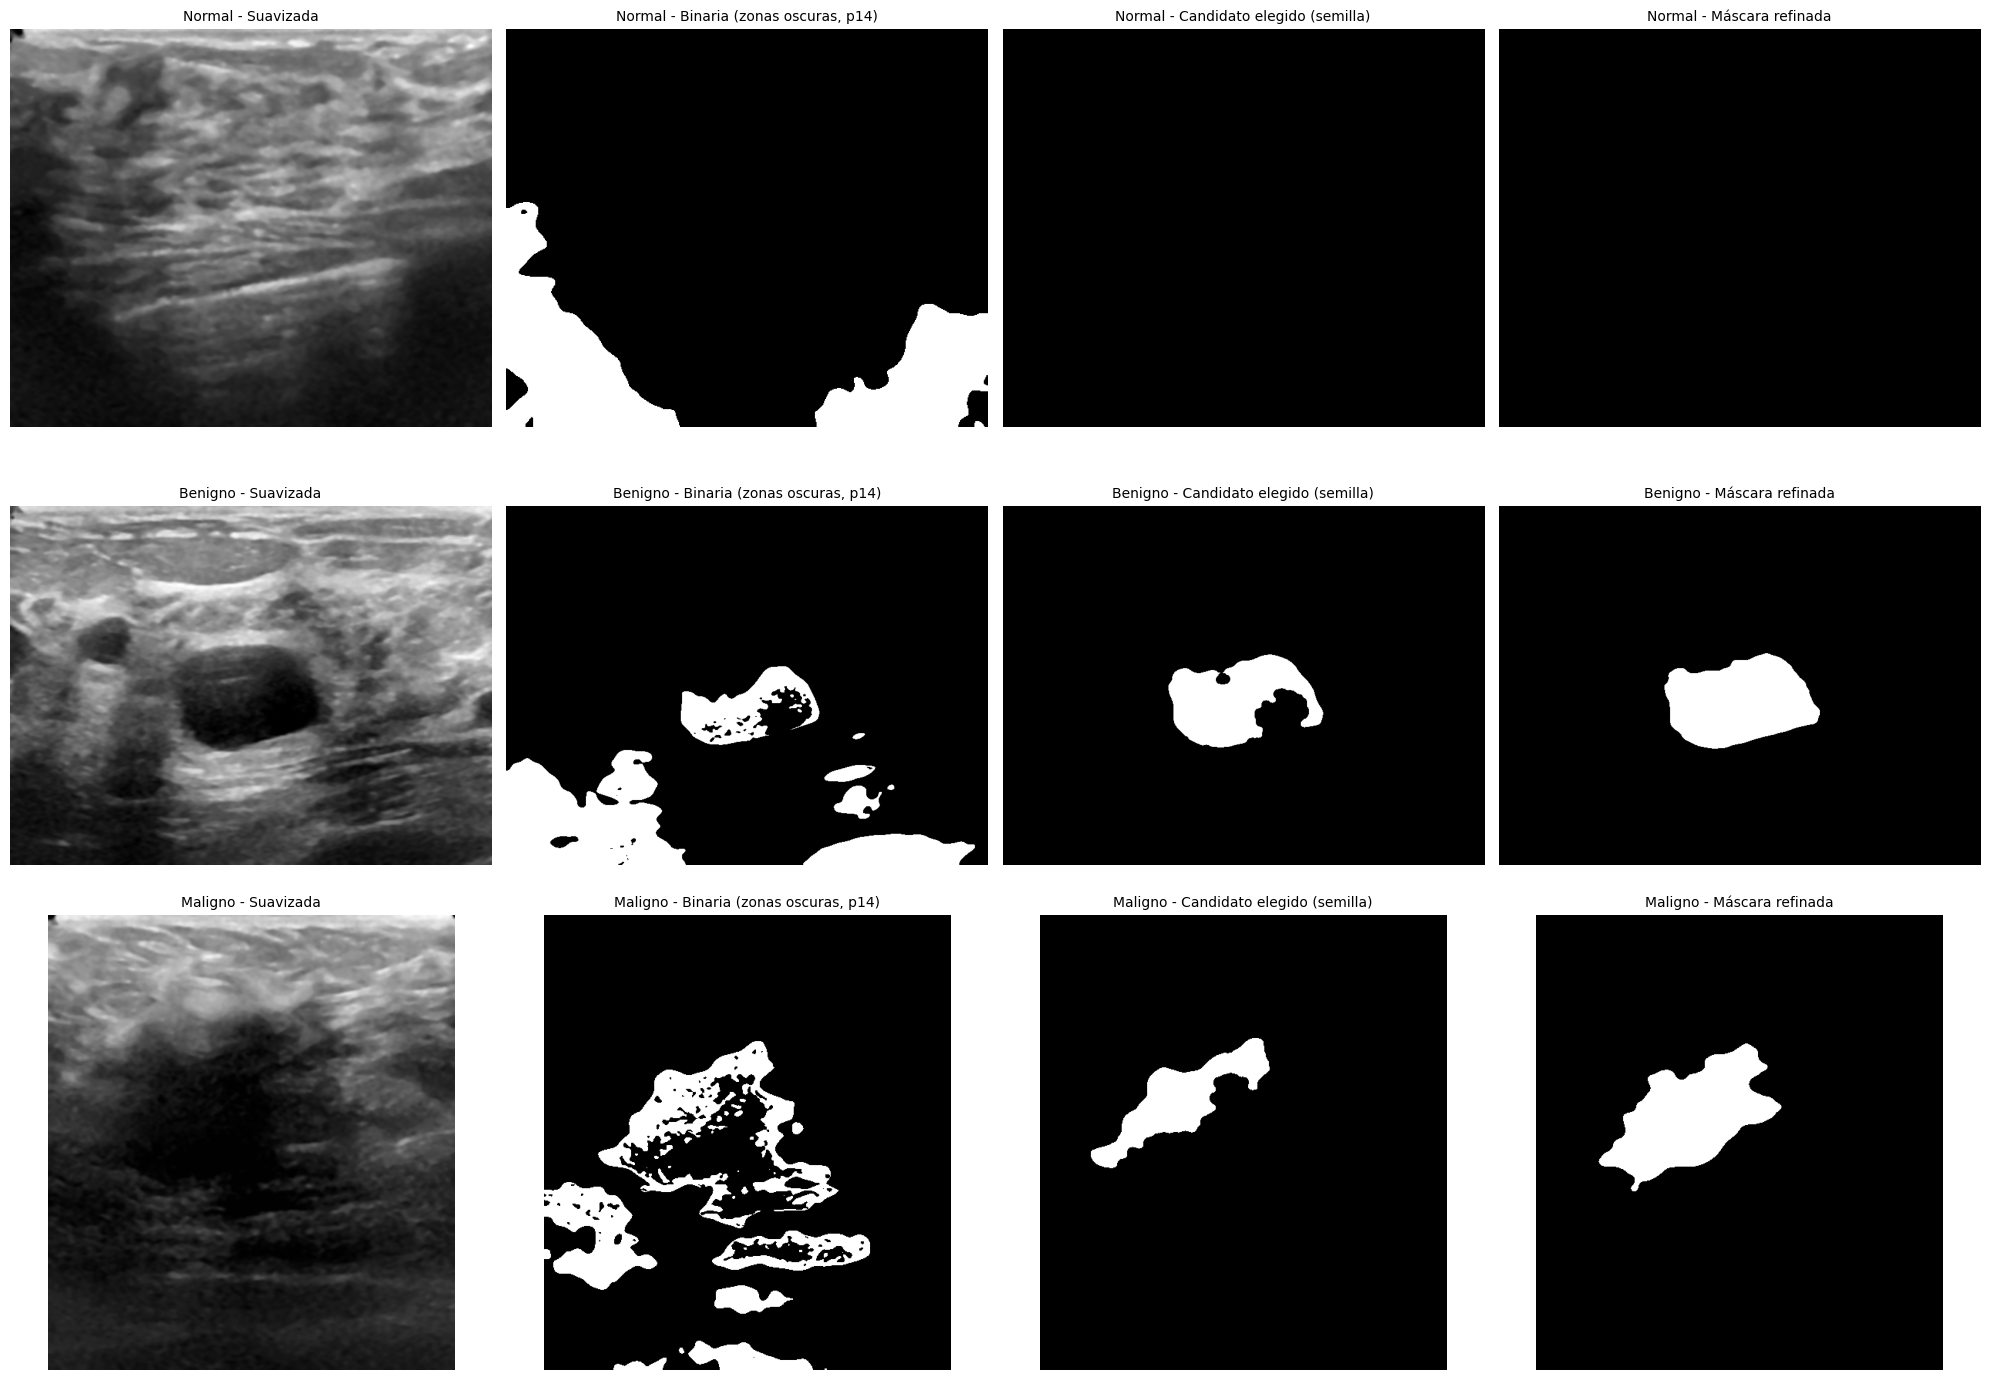

In [65]:
fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for fila, cat in enumerate(categorias):
    suave = suavizadas[cat]
    bin_oscura = binaria_por_percentil(suave, 14)
    r = preprocesar(datos[cat][0])
    for ax, (t, im) in zip(axes[fila], [
        ("Suavizada", suave),
        ("Binaria (zonas oscuras, p14)", bin_oscura),
        ("Candidato elegido (semilla)", r["semilla"]),
        ("Máscara refinada", r["mascara"]),
    ]):
        ax.imshow(im, cmap="gray"); ax.set_title(f"{NOMBRES[cat]} - {t}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

# 4. Evaluación de resultados

In [58]:
def comparar_mascaras(mascara_predicha, mascara_real):
    """
    Compara la máscara generada con la máscara de referencia del dataset.
    Calcula diferencias numéricas de píxeles y métricas de segmentación.
    """
    # Asegurar que sean binarias (0 y 255)
    pred = (mascara_predicha > 127).astype(np.uint8)
    real = (mascara_real > 127).astype(np.uint8)

    # 1. Conteo de píxeles de lesión
    pixeles_predicha = int(np.sum(pred))
    pixeles_real = int(np.sum(real))
    diferencia_absoluta = abs(pixeles_predicha - pixeles_real)

    # 2. Píxeles de diferencia (Falsos Positivos y Falsos Negativos)
    # Falsos Positivos: Pixeles que detectaste pero NO estaban en la real
    fp = int(np.sum((pred == 1) & (real == 0)))

    # Falsos Negativos: Pixeles de la lesión real que TE FALTARON por detectar
    fn = int(np.sum((pred == 0) & (real == 1)))

    # Verdaderos Positivos: Pixeles donde coincidieron correctamente
    tp = int(np.sum((pred == 1) & (real == 1)))

    # Total de píxeles en desacuerdo/diferentes
    pixeles_diferentes = fp + fn

    # 3. Métrica IoU (Jaccard) y Dice
    union = tp + fp + fn
    iou = tp / union if union > 0 else (1.0 if pixeles_real == 0 and pixeles_predicha == 0 else 0.0)
    dice = (2 * tp) / (2 * tp + fp + fn) if union > 0 else (1.0 if pixeles_real == 0 and pixeles_predicha == 0 else 0.0)

    return {
        "pixeles_real": pixeles_real,
        "pixeles_predicha": pixeles_predicha,
        "diferencia_absoluta": diferencia_absoluta,
        "falsos_positivos_px": fp,
        "falsos_negativos_px": fn,
        "total_pixeles_diferentes": pixeles_diferentes,
        "iou": iou,
        "dice": dice
    }

--- Categoría Normal ---
 Píxeles Reales: 0
 Píxeles Predichos: 0
 Píxeles de Diferencia (FP + FN): 0 px
 Falsos Positivos (sobrantes): 0 px
 Falsos Negativos (faltantes): 0 px
 Índice IoU (Jaccard): 1.0000

--- Categoría Benigno ---
 Píxeles Reales: 32243
 Píxeles Predichos: 26679
 Píxeles de Diferencia (FP + FN): 6234 px
 Falsos Positivos (sobrantes): 335 px
 Falsos Negativos (faltantes): 5899 px
 Índice IoU (Jaccard): 0.8086

--- Categoría Maligno ---
 Píxeles Reales: 74179
 Píxeles Predichos: 21693
 Píxeles de Diferencia (FP + FN): 52752 px
 Falsos Positivos (sobrantes): 133 px
 Falsos Negativos (faltantes): 52619 px
 Índice IoU (Jaccard): 0.2901



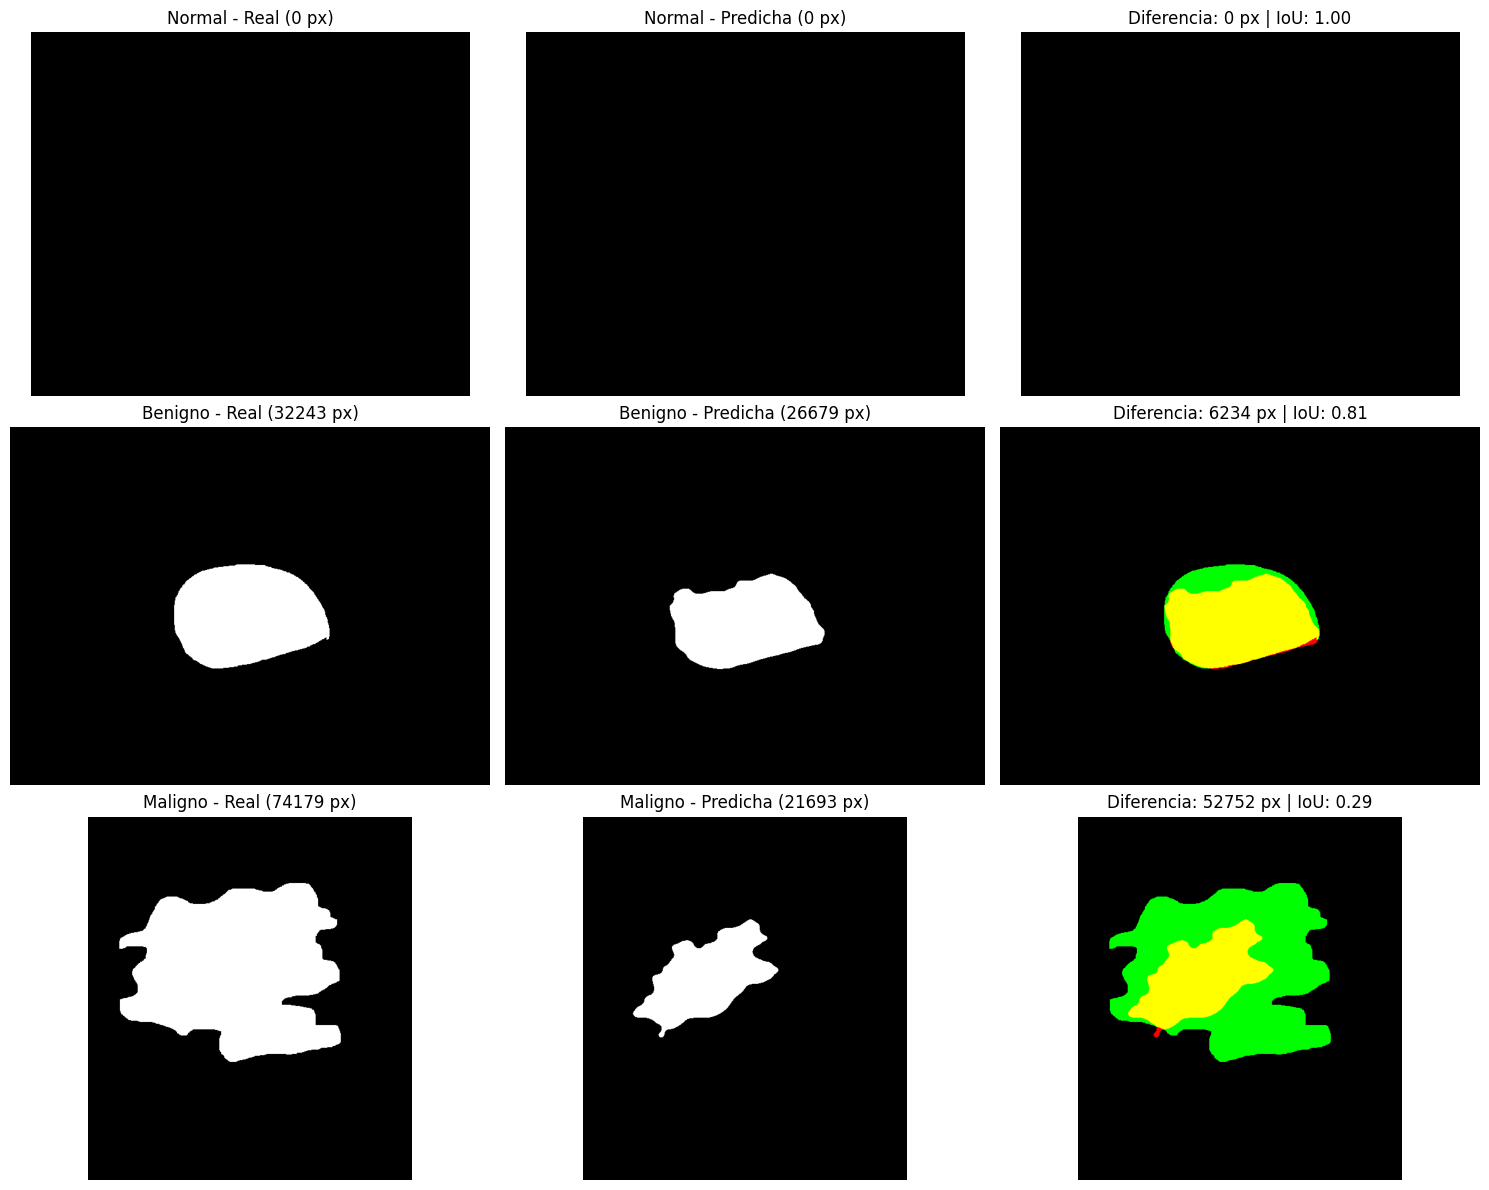

In [59]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for fila, cat in enumerate(categorias):
    img_orig, msk_real = datos[cat]  # Máscara de referencia del dataset
    r = preprocesar(img_orig)
    msk_pred = r["mascara"]          # Tu máscara refinada

    # Calcular métricas de diferencia
    res = comparar_mascaras(msk_pred, msk_real)

    # Crear imagen RGB para ver coincidencias y errores:
    # Verde = Real | Rojo = Predicha | Amarillo = Solapamiento (Coincidencia)
    h, w = msk_real.shape
    superposicion = np.zeros((h, w, 3), dtype=np.uint8)
    superposicion[..., 0] = (msk_pred > 127) * 255  # Canal Rojo: Predicción
    superposicion[..., 1] = (msk_real > 127) * 255  # Canal Verde: Real

    # Mostrar imágenes
    axes[fila, 0].imshow(msk_real, cmap="gray")
    axes[fila, 0].set_title(f"{NOMBRES[cat]} - Real ({res['pixeles_real']} px)")

    axes[fila, 1].imshow(msk_pred, cmap="gray")
    axes[fila, 1].set_title(f"{NOMBRES[cat]} - Predicha ({res['pixeles_predicha']} px)")

    axes[fila, 2].imshow(superposicion)
    axes[fila, 2].set_title(f"Diferencia: {res['total_pixeles_diferentes']} px | IoU: {res['iou']:.2f}")

    for ax in axes[fila]:
        ax.axis("off")

    print(f"--- Categoría {NOMBRES[cat]} ---")
    print(f" Píxeles Reales: {res['pixeles_real']}")
    print(f" Píxeles Predichos: {res['pixeles_predicha']}")
    print(f" Píxeles de Diferencia (FP + FN): {res['total_pixeles_diferentes']} px")
    print(f" Falsos Positivos (sobrantes): {res['falsos_positivos_px']} px")
    print(f" Falsos Negativos (faltantes): {res['falsos_negativos_px']} px")
    print(f" Índice IoU (Jaccard): {res['iou']:.4f}\n")

plt.tight_layout()
plt.show()

# 5. Conclusiones

• El pipeline morfológico demostró una precisión perfecta en pacientes Normales (IoU: 1.00) al descartar correctamente la presencia de lesiones, y una alta efectividad en lesiones Benignas (IoU: 0.81) debido a sus contornos regulares y definidos.


• Se identificó una caída drástica en el rendimiento para la categoría Maligno (IoU: 0.29). El algoritmo sufrió un alto número de Falsos Negativos (52,619 px) porque las lesiones malignas son altamente irregulares y se confunden fácilmente con el tejido denso circundante o la sombra acústica posterior del ultrasonido.


• Las etapas iniciales de Inpainting (Top-Hat) y el filtrado híbrido (Mediana + Gaussiano) cumplieron exitosamente su objetivo eliminando artefactos de texto (ej. "RIGHT BREAST") y mitigando el ruido speckle sin destruir los bordes anatómicos clave.
